<a href="https://colab.research.google.com/github/perk-bevis/understanding-transformers/blob/main/transformel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from transformers import pipeline

pipe = pipeline(
    "text-generation",
    model="openai-community/gpt2"
)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
prompt = "What is machine learning?"
result = pipe(prompt)
print(result)

[{'generated_text': "What is machine learning?\n\nMachine learning is a process that is designed to predict, predict, predict. This includes what you say and what you think and what you think about, but it can also include things like what you think is true and what is true and what is false. Machine learning is a process that is designed to predict, predict, predict. It involves the use of inference techniques that are built into the AI to predict what you are going to say.\n\nThere are two main categories of machine learning, which we'll explore in a moment. The first category is called deep learning. Deep learning is a technique that's built on the principle that if it's good, it will be good. It works by taking the input data and generating a model based on it. This is called deep learning.\n\nIn this example, I'm doing a function that looks like this:\n\ndef main() { if (my_input.is_bad) { my_input = my_input.next(); my_input.set_value(1); } else { } }\n\nNow, the function returns

In [ ]:
print(result[0]["generated_text"])

What is machine learning?

Machine learning is a process that is designed to predict, predict, predict. This includes what you say and what you think and what you think about, but it can also include things like what you think is true and what is true and what is false. Machine learning is a process that is designed to predict, predict, predict. It involves the use of inference techniques that are built into the AI to predict what you are going to say.

There are two main categories of machine learning, which we'll explore in a moment. The first category is called deep learning. Deep learning is a technique that's built on the principle that if it's good, it will be good. It works by taking the input data and generating a model based on it. This is called deep learning.

In this example, I'm doing a function that looks like this:

def main() { if (my_input.is_bad) { my_input = my_input.next(); my_input.set_value(1); } else { } }

Now, the function returns true if the input is bad and f

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2", device_map="auto")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
model


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
from transformers import AutoTokenizer
import torch
import torch.nn.functional as F

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("gpt2")

In [ ]:
sentence = "unsure"
input_ids = tokenizer(sentence ,return_tensors="pt")["input_ids"]
input_ids

tensor([[13271,   495]])

In [ ]:
tokenizer.decode(input_ids[0])


'unsure'

In [ ]:
sentence = "unbelivable"
input_ids = tokenizer(sentence ,return_tensors="pt").input_ids
input_ids

tensor([[  403,  6667, 21911]])

In [ ]:
for token_id in input_ids[0]:
    print(tokenizer.decode(token_id))

un
bel
ivable


In [ ]:
word = "homoscedasticity"
my_ids = tokenizer(word, return_tensors="pt").input_ids
my_ids

tensor([[26452,   418,   771,  3477,   414]])

In [ ]:
tokenizer.decode(my_ids.squeeze())

'homoscedasticity'

In [ ]:
word = "pneumonoultramicroscopicsilicovolcanoconiosis"
my_ids = tokenizer(word, return_tensors="pt").input_ids
# len(my_ids[0])
my_ids

tensor([[   79, 25668,   261, 25955,   859,  2500,  1416,   404,   873, 41896,
           709,   349,  5171, 36221, 42960]])

In [ ]:
for token_id in my_ids.squeeze():
    print(tokenizer.decode(token_id))

p
neum
on
oult
ram
icro
sc
op
ics
ilic
ov
ol
can
ocon
iosis


In [ ]:
sentence = "antidisestablishmentarianism"
token_ids = tokenizer(sentence, return_tensors="pt").input_ids
token_ids, len(token_ids[0])

(tensor([[  415, 29207, 44390,  3699,  1042]]), 5)

In [ ]:

word = "floccinaucinihilipilification"

my_ids = tokenizer(word, return_tensors="pt").input_ids
my_ids, len(my_ids[0])

(tensor([[ 2704, 13966,   259, 14272,   259, 20898,   541,   346,  2649]]), 9)

In [ ]:

for token_id in my_ids[0]:
    print(tokenizer.decode(token_id))

fl
occ
in
auc
in
ihil
ip
il
ification


In [ ]:
from transformers import AutoModelForCausalLM

In [ ]:
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:

gpt2

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
sentence = "I like machine learning to be able to predict the future."
# Data Processing technique
token_ids = tokenizer(sentence, return_tensors="pt").input_ids

outputs = gpt2(token_ids).logits[0, -1]
tokenizer.decode(outputs.argmax())

'\n'

In [ ]:

sentence = "I learn machine learning to enhance our understanding of the world around us."

token_ids = tokenizer(sentence, return_tensors="pt").input_ids

outputs = gpt2(token_ids).logits[0, -1]
tokenizer.decode(outputs.argmax())

'\n'

In [ ]:
sentence = "I learn machine learning to enhance"
token_ids = tokenizer(sentence, return_tensors="pt").input_ids
outputs = gpt2(token_ids).logits[0, -1]
final_logits = torch.topk(outputs, 20) # Feel free to play around with the K

for index in final_logits.indices:
    print(tokenizer.decode(index))

 our
 the
 my
 your
 human
 a
 and
 its
 their
 performance
 learning
 user
 data
 social
 real
 understanding
 information
,
 intelligence
 people


In [ ]:
torch.softmax(final_logits.values, dim=0).sum()

tensor(1., grad_fn=<SumBackward0>)

In [ ]:
torch.softmax(final_logits.values, dim=0).sum()

tensor(1., grad_fn=<SumBackward0>)

In [ ]:
def greedy_decode(logits):
    """Return token index with maximum probability."""
    return torch.argmax(logits, dim=-1)

# TOP K SAMPLING

def top_k_sampling(logits, k=50):
    """
    keeps only top-k logits, normalize them into probability.
    them sample one token from the filtered distribution.
    """
    values, indices = torch.topk(logits, k)
    probs = F.softmax(values, dim=-1)
    sampled = torch.multinomial(probs, 1)
    return indices[sampled]

# Top-p (Nuecles) Sampling

def top_p_sampling(logits, p=0.9):
    """
    Sort tokens by probability, keep smallest number whose culumative
    probability exceeds threshold p, then sample one token.
    """

    sorted_logits, sorted_indices = torch.sort(logits, descending=True)
    sorted_probs = F.softmax(sorted_logits, dim=-1)
    cumulative_probs = sorted_probs.cumsum(dim=-1)

    # Mask token outside nuclues
    mask = cumulative_probs > p
    sorted_logits[mask] = float("-inf")

    # Sample from filtered logits
    filtered_probs = F.softmax(sorted_logits, dim=-1)
    sampled = torch.multinomial(filtered_probs, 1)

    # Return token index in originial vocabulary
    return sorted_indices[sampled]

## Temperature Sampling ##

def temperature_sampling(logits, temperature=1.0):
    """
    Scale logits by temperature before sampling.
    Lower temperature => sharper distribution
    """

    scaled = logits / temperature
    probs = F.softmax(scaled, dim=-1)
    return torch.multinomial(probs, 1)


## Random Sampling ##

def random_sampling(logits):
    """
    Sample dirctly from softmax distribution without filtring
    """

    probs = F.softmax(logits, dim=-1)
    return torch.multinomial(probs, 1)

# sentence = "Today I decided to go to the local library and find out what was in my wallet."
sentence = "I am really happy becuase I have gone back in time."
inputs = tokenizer(sentence, return_tensors="pt")
output = gpt2(**inputs)
logits = output.logits[0, -1]

print(f"Greedy Decode: ", tokenizer.decode([greedy_decode(logits)]))
print(f"Top-K Sampling: ", tokenizer.decode(top_k_sampling(logits, k=10)))
print(f"Top-P-Sampling: ", tokenizer.decode(top_p_sampling(logits, p=0.9)))
print(f"Temp: ", tokenizer.decode(temperature_sampling(logits, temperature=1)))
print(f"Radnom: ", tokenizer.decode(random_sampling(logits)))

Greedy Decode:   I
Top-K Sampling:   It
Top-P-Sampling:   I
Temp:   So
Radnom:   I


In [ ]:
tokenizer.decode(top_k_sampling(outputs))

' your'

In [ ]:
outputs

tensor([-109.4038, -108.0284, -114.4298,  ..., -111.9259, -117.0069,
        -109.9712], grad_fn=<SelectBackward0>)

In [ ]:

tokenizer.decode(top_p_sampling(outputs, p=0.9))

' the'

In [ ]:
tokenizer.decode(temperature_sampling(outputs, temperature=1.5))

' Borg'

In [ ]:
tokenizer.decode(random_sampling(outputs))

' communication'

In [ ]:
sentence = "I learn machine learning to enhance our understanding of the brain in"
token_ids = tokenizer(sentence, return_tensors="pt").input_ids
outputs = gpt2(token_ids).logits # Raw Unnormlized Score - Values
outputs = torch.softmax(outputs[0, -1], dim=-1)

top10 = torch.topk(outputs, k=10)

for index, value in zip(top10.indices, top10.values):
    print(f"{tokenizer.decode(index)} -- {value:.1%}")

 a -- 14.7%
 the -- 7.7%
 order -- 6.2%
 ways -- 6.2%
 general -- 4.5%
 humans -- 2.9%
 many -- 2.8%
 an -- 2.4%
 our -- 2.3%
 everyday -- 1.7%


In [ ]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("text-generation", model="openai-community/gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:

prompt = "What is machine learning?"
output = pipe(prompt)

In [ ]:
print(output[0]["generated_text"])

What is machine learning?

Machine learning refers to the process by which a machine learns to distinguish itself from a human. It is a system of data structures called neural networks. Every machine learning system needs to be able to distinguish between objects and information. This is a crucial step needed to identify the right object for the task.

This is a fundamental process that is essential for human survival. A robot that can distinguish itself from a human is a better human.

In the machine learning world, it's almost impossible to distinguish between two people. But in humans, it's just so easy.

In the machine learning world, it's almost impossible to identify between two people. But in humans, it's just so easy.

Imagine you have a very good computer in your home, and it has a problem that you believe is not related to one another, but is at the same time related to a person. It has to know what to do next, because it knows that a person is a better person.

If you want t

In [ ]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
model

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

Sentiment Analysis

In [ ]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
type(ds)

datasets.dataset_dict.DatasetDict

In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [ ]:
ds["train"]

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

In [ ]:
import pandas as pd

In [ ]:
ds["train"].to_pandas()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
...,...,...
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1


In [ ]:
my_dataset_df = ds["train"].to_pandas()

In [ ]:
my_dataset_df["text"]

,text
0,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...
3,This film was probably inspired by Godard's Ma...
4,"Oh, brother...after hearing about this ridicul..."
...,...
24995,A hit at the time but now better categorised a...
24996,I love this movie like no other. Another time ...
24997,This film and it's sequel Barry Mckenzie holds...
24998,'The Adventures Of Barry McKenzie' started lif...


In [ ]:
len(my_dataset_df["text"])

25000

In [ ]:
from transformers import pipeline

In [ ]:
classifier = pipeline("sentiment-analysis")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

In [ ]:
classifier("This day is great!")

[{'label': 'POSITIVE', 'score': 0.999881386756897}]

In [ ]:
classifier("This day is terrible and i am so sad")[0]["label"]

'NEGATIVE'

In [ ]:
def score(review_text):
    return classifier(review_text[:500])[0]["label"]

In [ ]:
my_dataset_df["model_prediction"] = my_dataset_df["text"].apply(score)

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [ ]:
my_dataset_df[["label", "model_prediction"]][:20]

,label,model_prediction
0,0,NEGATIVE
1,0,NEGATIVE
2,0,NEGATIVE
3,0,POSITIVE
4,0,NEGATIVE
5,0,NEGATIVE
6,0,NEGATIVE
7,0,NEGATIVE
8,0,NEGATIVE
9,0,NEGATIVE


In [ ]:
my_dataset_df.iloc[0]

,0
text,I rented I AM CURIOUS-YELLOW from my video sto...
label,0
model_prediction,NEGATIVE


In [ ]:
review = my_dataset_df.iloc[0]["text"]
classifier(review)[0]["label"]

'POSITIVE'

In [ ]:
from transformers import pipeline

In [ ]:
finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert")

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [ ]:
sentence = "The company reported a strong increase in quarterly revnue, exceeding market expectations."
finbert(sentence)

[{'label': 'positive', 'score': 0.951565146446228}]

In [ ]:
sentence = "Shares fell after the firm reported lower-than-expected earnings"
finbert(sentence)

[{'label': 'negative', 'score': 0.9718543887138367}]

In [ ]:
sentences = ["Strong consumer demand drove record sales across all regions",
             "Supply chain disruptions severly affected production output"]

In [ ]:
finbert(sentences)

[{'label': 'positive', 'score': 0.9434745907783508},
 {'label': 'negative', 'score': 0.9608097672462463}]

Named Entity Recognition

In [ ]:
sentence = "Apple announced record earnings in the United States on Monday."

In [ ]:
ner = pipeline("ner")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

In [ ]:
sentence

'Apple announced record earnings in the United States on Monday.'

In [ ]:
ner(sentence)

[{'entity': 'I-ORG',
  'score': np.float32(0.9991387),
  'index': 1,
  'word': 'Apple',
  'start': 0,
  'end': 5},
 {'entity': 'I-LOC',
  'score': np.float32(0.9997105),
  'index': 7,
  'word': 'United',
  'start': 39,
  'end': 45},
 {'entity': 'I-LOC',
  'score': np.float32(0.99967074),
  'index': 8,
  'word': 'States',
  'start': 46,
  'end': 52}]

In [ ]:
sentence = "I live in UK worked at Facebook after graduating from Harvard"

In [ ]:
ner(sentence)

[{'entity': 'I-LOC',
  'score': np.float32(0.9997962),
  'index': 4,
  'word': 'UK',
  'start': 10,
  'end': 12},
 {'entity': 'I-ORG',
  'score': np.float32(0.9983279),
  'index': 7,
  'word': 'Facebook',
  'start': 23,
  'end': 31},
 {'entity': 'I-ORG',
  'score': np.float32(0.9209187),
  'index': 11,
  'word': 'Harvard',
  'start': 54,
  'end': 61}]

**Question Answering**

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

# 1. Tải tokenizer và model chuẩn của distilbert cho extractive QA
model_name = "distilbert/distilbert-base-uncased-distilled-squad"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForQuestionAnswering.from_pretrained(model_name)

# 2. Định nghĩa context và các câu hỏi
context = """
Financial sentiment analysis is a challenging task due to the specialized
language and lack of labeled data in that domain. General-purpose models are
not effective enough because of the specialized language used in a financial
context. We hypothesize that pre-trained language models can help with this
problem because they require fewer labeled examples and they can be further
trained on domain-specific corpora. We introduce FinBERT, a language model
based on BERT, to tackle NLP tasks in the financial domain. Our results show
improvement in every measured metric on current state-of-the-art results for
two financial sentiment analysis datasets. We find that even with a smaller
training set and fine-tuning only a part of the model, FinBERT outperforms
state-of-the-art machine learning methods.
"""

# Hàm phụ trợ giúp gọi nhanh gọn giống hệt cách cũ của bạn
def qa_bot(question, context):
    # Tokenize đầu vào gồm cả question và context
    inputs = tokenizer(question, context, return_tensors="pt")

    # Dự đoán vị trí bắt đầu và kết thúc của câu trả lời
    with torch.no_grad():
        outputs = model(**inputs)

    answer_start = torch.argmax(outputs.start_logits)
    answer_end = torch.argmax(outputs.end_logits) + 1

    # Cắt chuỗi token trả về câu trả lời chính xác
    answer = tokenizer.convert_tokens_to_string(
        tokenizer.convert_ids_to_tokens(inputs["input_ids"][0][answer_start:answer_end])
    )

    # Trả về dạng dictionary giống hệt pipeline cũ để bạn dùng result["answer"]
    return {"answer": answer}

# 3. Chạy thử nghiệm với các câu hỏi của bạn
question = "What is financial sentiment analysis?"
result = qa_bot(question=question, context=context)
print(result["answer"])

question = "What is FinBERT?"
result = qa_bot(question=question, context=context)
print(result["answer"])

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  265MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

a challenging task
a language model based on bert


**Machine** **Translation**

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1. Tải tokenizer và model NLLB chuẩn trực tiếp (chỉ định rõ src_lang là tiếng Anh)
model_name = "facebook/nllb-200-distilled-600M"
tokenizer = AutoTokenizer.from_pretrained(model_name, src_lang="eng_Latn")
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# 2. Định nghĩa hàm dịch thuật đơn giản, gọn gàng
def translater(text):
    # Tokenize câu nguồn
    inputs = tokenizer(text, return_tensors="pt")

    # Dịch sang tiếng Pháp (fra_Latn)
    translated_tokens = model.generate(
        **inputs,
        forced_bos_token_id=tokenizer.convert_tokens_to_ids("fra_Latn"),
        max_length=50
    )

    # Giải mã token thành văn bản
    translated_text = tokenizer.decode(translated_tokens[0], skip_special_tokens=True)
    return translated_text

# 3. Chạy thử nghiệm các câu lệnh của bạn
print(translater("Hello"))
print(translater("Thanks"))

sentence = "What is your name?"
print(translater(sentence))

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Je vous salue .
Merci .
Comment vous appelez-vous ?


**audio processing using python**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import librosa

In [ ]:

audio_path = "audio.mp3"
y, sr = librosa.load(audio_path)

In [ ]:
y

array([0.00025094, 0.00028213, 0.00019896, ..., 0.0014153 , 0.00130616,
       0.00040388], dtype=float32)

In [ ]:
y[:100]

array([ 2.5093951e-04,  2.8213154e-04,  1.9896177e-04,  1.5101006e-04,
        5.8936886e-05, -1.7069632e-04, -4.7867373e-04, -7.3832081e-04,
       -8.3403615e-04, -8.2674436e-04, -8.4082980e-04, -8.2562614e-04,
       -7.3050032e-04, -6.0832396e-04, -4.8463899e-04, -4.2319502e-04,
       -4.5133673e-04, -4.3832485e-04, -3.9548555e-04, -4.9832615e-04,
       -6.8613834e-04, -7.7582989e-04, -7.9931441e-04, -8.6572632e-04,
       -9.7776251e-04, -1.0772429e-03, -1.1465414e-03, -1.2982440e-03,
       -1.5856571e-03, -1.7763639e-03, -1.7024061e-03, -1.5696600e-03,
       -1.5436797e-03, -1.4985959e-03, -1.3792455e-03, -1.2861583e-03,
       -1.2200586e-03, -1.1489197e-03, -1.1465386e-03, -1.2504128e-03,
       -1.3732718e-03, -1.4082482e-03, -1.3469425e-03, -1.2767510e-03,
       -1.2162974e-03, -1.0912751e-03, -9.5056969e-04, -9.1160700e-04,
       -9.1240340e-04, -8.5790723e-04, -8.2171068e-04, -8.6497003e-04,
       -9.3751121e-04, -1.0059046e-03, -1.0516576e-03, -1.0531922e-03,
      

In [ ]:
y.shape

(404177,)

In [ ]:
sr

22050

Text(0, 0.5, 'amplitude')

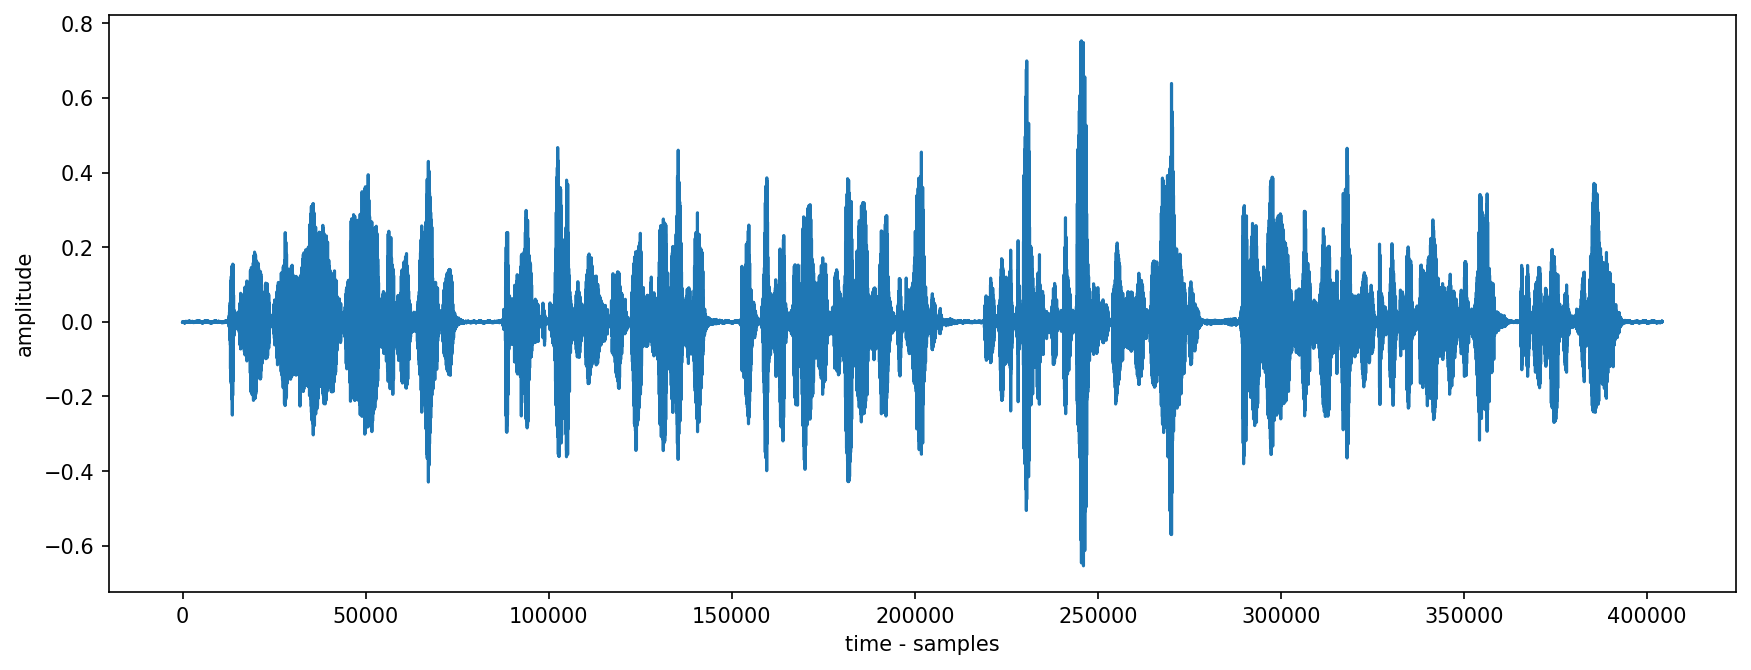

In [ ]:
plt.figure(figsize=(14,5),dpi=150)
plt.plot(y)
plt.xlabel("time - samples")
plt.ylabel("amplitude")